# Módulo 08: Sedimentación y Colmatación en Embalses (`sedmor.sedimentation`)

La pérdida progresiva de capacidad útil en embalses por depósito de gravas, arenas, limos y arcillas se modela discretizando el vaso en compartimentos longitudinales en serie mediante `reservoir_sedimentation` y `ReservoirSectionInput`.

### Objetivos de aprendizaje
1. Configurar un embalse multi-sección (`ReservoirSectionInput`) con hidrograma mensual y carga de arcilla, limo y arena.
2. Comparar las estimaciones de atrapamiento y colmatación obtenidas con los métodos **`van_rijn`**, **`eysink_vermaas`** y **`borland`** (`SEDRES.xlsx`).
3. Analizar el recrecimiento del fondo $\Delta h$ y la pérdida porcentual de volumen a lo largo del eje del embalse.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sedmor as sm

plt.rcParams["figure.dpi"] = 110
print(f"Librería sedmor v{sm.__version__} cargada.")


Librería sedmor v0.1.0 cargada.


## 1. Simulación Multi-Sección y Comparación de Tres Métodos de Atrapamiento

Definimos un embalse de 5 tramos desde la cola (sección 1) hasta la presa (sección 5), sometido a un ciclo hidrológico anual de 12 meses con crecidas estacionales.


In [2]:
sections = [
    sm.sedimentation.ReservoirSectionInput(length_m=1050.0, width_m=170.0, depth_drop_m=8.2),
    sm.sedimentation.ReservoirSectionInput(length_m=950.0, width_m=300.0, depth_drop_m=8.5),
    sm.sedimentation.ReservoirSectionInput(length_m=550.0, width_m=415.0, depth_drop_m=4.5),
    sm.sedimentation.ReservoirSectionInput(length_m=1350.0, width_m=245.0, depth_drop_m=10.0),
    sm.sedimentation.ReservoirSectionInput(length_m=1000.0, width_m=340.0, depth_drop_m=11.7),
]

# Hidrograma estacional de 12 pasos (días, caudales y concentraciones en kg/m3)
days = [30.0] * 12
Q_in = [60, 75, 110, 180, 240, 210, 140, 95, 75, 65, 55, 50]
h0_in = [2.4, 2.6, 3.0, 3.8, 4.3, 4.0, 3.3, 2.8, 2.6, 2.5, 2.3, 2.2]
c_clay = [0.10, 0.12, 0.16, 0.25, 0.32, 0.28, 0.18, 0.13, 0.11, 0.10, 0.09, 0.08]
c_silt = [0.05, 0.07, 0.10, 0.18, 0.24, 0.20, 0.12, 0.08, 0.06, 0.05, 0.04, 0.04]
c_sand = [0.01, 0.02, 0.03, 0.07, 0.10, 0.08, 0.04, 0.02, 0.01, 0.01, 0.01, 0.01]

res_by_method = {}
for m in ["van_rijn", "eysink_vermaas", "borland"]:
    r = sm.sedimentation.reservoir_sedimentation(
        sections=sections, days=days, discharge=Q_in, h0=h0_in,
        c_clay=c_clay, c_silt=c_silt, c_sand=c_sand,
        river_width=70.0, ws_clay=0.0001, ws_silt=0.001, ws_sand=0.015, chezy=65.0, method=m
    )
    res_by_method[m] = r
    print(f"{m:15s} -> Vol retenido: {r.total_deposition_capped_m3:10,.0f} m³/año | Eficiencia global: {r.overall_trapping_efficiency*100:5.1f}%")


van_rijn        -> Vol retenido:  1,644,629 m³/año | Eficiencia global:  95.6%
eysink_vermaas  -> Vol retenido:  1,700,881 m³/año | Eficiencia global:  98.9%
borland         -> Vol retenido:    917,897 m³/año | Eficiencia global:  53.4%


## 2. Perfil Longitudinal de Depósito y Exportación por el Aliviadero

Visualizamos el recrecimiento acumulado $\Delta h$ por tramo (observando cómo la arena decanta rápidamente en los tramos iniciales mientras arcilla y limo alcanzan la presa) y la serie mensual de concentración saliente por el vertedero.


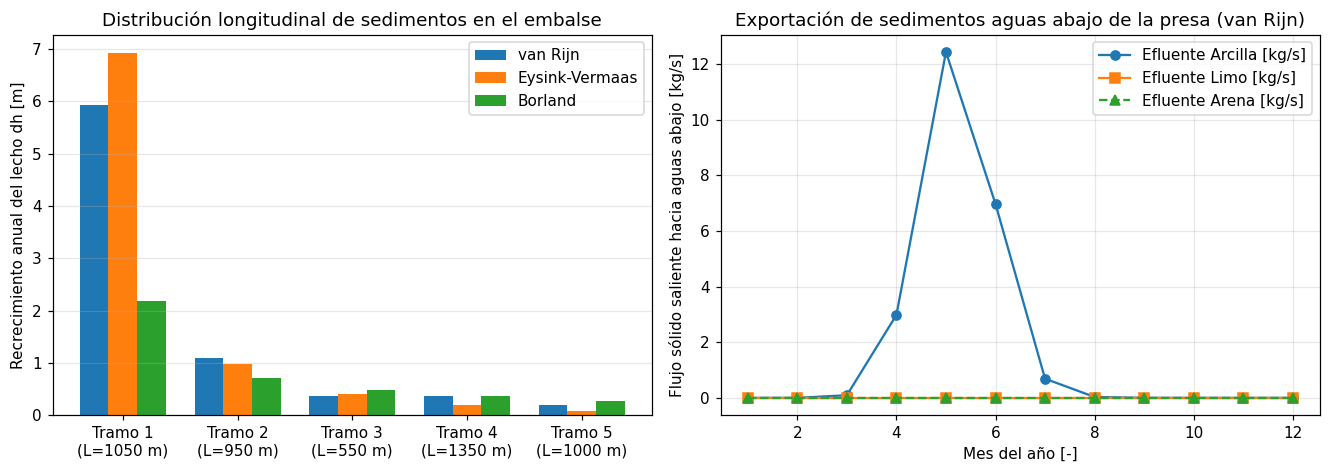

In [3]:
sec_ids = np.arange(1, len(sections) + 1)
meses = np.arange(1, 13)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.2, 4.4))

w = 0.25
for k, (m, lbl) in enumerate([("van_rijn", "van Rijn"), ("eysink_vermaas", "Eysink-Vermaas"), ("borland", "Borland")]):
    dh_sec = [s.total_dh_m for s in res_by_method[m].sections]
    ax1.bar(sec_ids + (k - 1) * w, dh_sec, width=w, label=lbl)

ax1.set_xticks(sec_ids)
ax1.set_xticklabels([f"Tramo {i}\n(L={s.length_m:.0f} m)" for i, s in enumerate(sections, 1)])
ax1.set_ylabel("Recrecimiento anual del lecho dh [m]")
ax1.set_title("Distribución longitudinal de sedimentos en el embalse")
ax1.grid(alpha=0.3, axis="y")
ax1.legend()

r_vr = res_by_method["van_rijn"]
ax2.plot(meses, r_vr.outflow_clay_kg_s, "o-", label="Efluente Arcilla [kg/s]")
ax2.plot(meses, r_vr.outflow_silt_kg_s, "s-", label="Efluente Limo [kg/s]")
ax2.plot(meses, r_vr.outflow_sand_kg_s, "^--", label="Efluente Arena [kg/s]")
ax2.set_xlabel("Mes del año [-]")
ax2.set_ylabel("Flujo sólido saliente hacia aguas abajo [kg/s]")
ax2.set_title("Exportación de sedimentos aguas abajo de la presa (van Rijn)")
ax2.grid(alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()


### Ejercicios propuestos
1. Modifique la velocidad de caída `ws_clay` (simulando mayor floculación por salinidad/electrolitos) a `0.0005 m/s` y observe el cambio en el flujo sólido efluente de arcilla.
2. Simule una serie multianual duplicando las duraciones `days` (por ejemplo 5 años) y compare el `consolidation_factor` aplicado sobre la densidad aparente del depósito.
